# Задание № 3. Прикладные дифференциальные уравнения



Для каждой задачи приведены: 1) аналитическое решение в разметке Markdown/LaTeX; 2) статическая визуализация (код + сохранение в png); 3) анимация на базе `matplotlib.animation.FuncAnimation`, встроенная в тетрадь через `to_jshtml()` — такой проигрыватель уже снабжён кнопками play/pause/шаг, что закрывает требование «возможность управления анимацией».

In [1]:
# Библиотеки, используемые во всех задачах тетради
import numpy as np                                   # численные вычисления
import matplotlib.pyplot as plt                       # построение графиков
import matplotlib.animation as animation               # анимации FuncAnimation
from matplotlib.patches import Circle                  # вспомогательная фигура (окружности, маятник)
from scipy.integrate import solve_ivp                   # численное интегрирование ОДУ (маятник)
from scipy.special import ellipk                        # полный эллиптический интеграл (период маятника)
from IPython.display import HTML, display               # встраивание интерактивного проигрывателя анимации

plt.rcParams['figure.figsize'] = (7, 5)
plt.rcParams['animation.embed_limit'] = 100             # лимит на размер встраиваемой анимации (Мб)
plt.rcParams['savefig.dpi'] = 80                         # пониженный dpi для кадров анимаций - меньше размер файла
g = 9.8                                                  # ускорение свободного падения, м/с^2
print('Библиотеки подключены, g =', g, 'м/с^2')

Библиотеки подключены, g = 9.8 м/с^2


## Задача 3.1. Кривая равномерного спуска

**Постановка.** Тяжёлая материальная точка под действием силы тяжести без трения скользит по кривой, расположенной в вертикальной плоскости $Oxy$ (ось $y$ направлена вверх). Требуется найти форму кривой, при движении по которой **вертикальная составляющая скорости точки постоянна**: $v_y=\dfrac{dy}{dt}=-c=\text{const}<0$ (точка равномерно опускается).

### 1) Аналитическое решение

Нормальная реакция кривой $N$ перпендикулярна скорости и работы не совершает, поэтому действует только сила тяжести — механическая энергия сохраняется:
$$\frac12 v^2+gy=\frac12 v_0^2+gy_0 \quad\Longrightarrow\quad v^2=v_0^2+2g(y_0-y).$$

Рассмотрим простейший случай, когда движение начинается сразу с требуемой вертикальной скоростью, направленной точно вниз: $v_{x}(0)=0,\; v_y(0)=-c$, так что $v_0=c$. Тогда
$$v^2=c^2+2g(y_0-y).$$

Поскольку $v_y=-c=\text{const}$, имеем $y(t)=y_0-ct$, откуda $y_0-y=ct$. Так как $v^2=v_x^2+v_y^2$, получаем
$$v_x^2=v^2-c^2=2g(y_0-y)=2gct \quad\Longrightarrow\quad v_x=\sqrt{2gct}.$$

Интегрируя $v_x=\dfrac{dx}{dt}$ по времени:
$$x(t)-x_0=\int_0^t\sqrt{2gc\,s}\,ds=\frac23\sqrt{2gc}\;t^{3/2}.$$

Исключая время при помощи $t=(y_0-y)/c$, получаем явное уравнение кривой:
$$\boxed{\;x-x_0=\frac{2\sqrt{2g}}{3c}\,(y_0-y)^{3/2}\;}\qquad\Longleftrightarrow\qquad (x-x_0)^2=\frac{8g}{9c^2}\,(y_0-y)^3.$$

Это уравнение **полукубической параболы** (параболы Нейля) с вершиной в начальной точке $(x_0,y_0)$: квадрат горизонтального смещения пропорционален кубу вертикального падения. Чем больше заданная постоянная скорость спуска $c$, тем «положе» кривая (меньше горизонтальное смещение при том же падении).

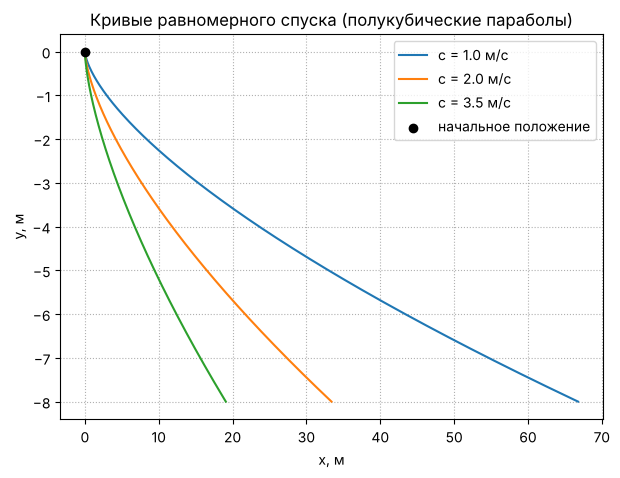

In [2]:
def neile_curve(y0, c, x0=0.0, n=300):
    # полукубическая парабола равномерного спуска: x - x0 = (2*sqrt(2g)/(3c)) * (y0-y)^(3/2)
    y = np.linspace(y0, y0 - 8, n)                      # точка опускается от y0 вниз на 8 м
    drop = y0 - y                                         # величина падения (y0 - y) >= 0
    x = x0 + (2*np.sqrt(2*g)/(3*c)) * drop**1.5           # явная формула кривой, выведенная выше
    return x, y

fig, ax = plt.subplots()
for c in [1.0, 2.0, 3.5]:                                 # несколько значений постоянной скорости спуска
    x, y = neile_curve(y0=0.0, c=c)
    ax.plot(x, y, label=f'c = {c} м/с')
ax.scatter([0], [0], color='black', zorder=5, label='начальное положение')  # начальная точка
ax.set_xlabel('x, м'); ax.set_ylabel('y, м')
ax.set_title('Кривые равномерного спуска (полукубические параболы)')
ax.grid(True, linestyle=':'); ax.legend()
fig.savefig('Sol_3_1_static.png', dpi=150, bbox_inches='tight')  # сохраняем статический рисунок в png
plt.show()

In [3]:
# Анимация: точка равномерно опускается по кривой Нейля, вертикальная скорость действительно постоянна
c_anim = 2.0                                              # постоянная скорость спуска для анимации
y0_anim = 0.0
T_total = np.sqrt(8/c_anim)                                # время спуска на 8 м при dy/dt=-c
n_frames = 50
t_vals = np.linspace(0, T_total, n_frames)
y_vals = y0_anim - c_anim*t_vals                            # y(t) = y0 - c*t (равномерный спуск по вертикали)
x_vals = (2*np.sqrt(2*g)/(3*c_anim)) * (c_anim*t_vals)**1.5 # x(t), подставив (y0-y)=c*t в формулу кривой

fig, ax = plt.subplots(figsize=(5.5, 4))
ax.plot(x_vals, y_vals, color='lightgray', linewidth=2, label='траектория')  # вся кривая заранее видна
point, = ax.plot([], [], 'o', color='crimson', markersize=10)
trace, = ax.plot([], [], '-', color='crimson', linewidth=1.5)
txt = ax.text(0.02, 0.95, '', transform=ax.transAxes, va='top')
ax.set_xlim(x_vals.min()-0.3, x_vals.max()+0.3); ax.set_ylim(y_vals.min()-0.3, 0.5)
ax.set_xlabel('x, м'); ax.set_ylabel('y, м'); ax.grid(True, linestyle=':')
ax.set_title('Анимация равномерного спуска по кривой Нейля')
ax.legend(loc='lower left')

def update(i):
    point.set_data([x_vals[i]], [y_vals[i]])              # текущее положение точки
    trace.set_data(x_vals[:i+1], y_vals[:i+1])             # пройденный путь
    vy_now = -c_anim                                        # вертикальная скорость остаётся постоянной
    txt.set_text(f't = {t_vals[i]:.2f} c\nv_y = {vy_now:.2f} м/с (постоянна)')
    return point, trace, txt

ani31 = animation.FuncAnimation(fig, update, frames=n_frames, interval=40, blit=True)
plt.close(fig)                                             # не показываем статический дубликат фигуры
HTML(ani31.to_jshtml())

**Вывод.** Кривая равномерного спуска — полукубическая парабола $x\propto(y_0-y)^{3/2}$; анимация выше подтверждает, что при движении по этой кривой $v_y$ действительно остаётся постоянной на всём пути.

## Задача 3.2. Бильярд в прямоугольнике

**Постановка.** Точка (бильярдный шар) движется без трения внутри прямоугольника со сторонами $a$ (по $x$) и $b$ (по $y$) с постоянной по модулю скоростью и упруго отражается от стенок (угол падения равен углу отражения).

### 1) Аналитическое решение

**Уравнения движения и граничные условия.** Между столкновениями $\ddot x=\ddot y=0$, т.е. $x(t)=x_0+v_x t,\; y(t)=y_0+v_y t$. При ударе о вертикальную стенку $x_{\text{комп.}}\to -x_{\text{комп.}}$ знак $v_x$ меняется на противоположный (аналогично для $v_y$ на горизонтальных стенках), модуль скорости сохраняется.

**Метод развёртки.** Вместо «отражения скорости» удобнее мысленно не отражать шар, а **отражать сам прямоугольник**: каждый раз, когда траектория должна удариться о стенку, мы продолжаем прямую линию в зеркально отражённую копию прямоугольника. Тогда траектория шара в исходном прямоугольнике получается из прямой линии
$$X(t)=x_0+v_xt,\qquad Y(t)=y_0+v_yt$$
на всей плоскости **периодическим зеркальным отражением** координат в полосы $[0,a]$ и $[0,b]$ (функция треугольной волны, реализована в коде ниже).

Эквивалентно, если отождествить противоположные стороны прямоугольника $2a\times2b$ (а не отразить, а «склеить» их), движение бильярда эквивалентно **прямолинейному равномерному движению точки на торе** $\mathbb T^2=\mathbb R^2/(2a\mathbb Z\times2b\mathbb Z)$.

**Периодичность и эргодичность.** Траектория на торе замкнута (периодична) тогда и только тогда, когда отношение скоростей $v_x/v_y$ **рационально**; если $v_x/v_y=p/q\in\mathbb Q$ (несократимая дробь), шар возвращается в начальную точку с той же скоростью после конечного числа отражений, и траектория — замкнутая ломаная. Если же $v_x/v_y$ **иррационально**, траектория никогда не замыкается и по теореме Вейля о равнораспределении **всюду плотно и равномерно** заполняет прямоугольник — это и есть эргодический случай.

**Гамильтонова формулировка.** Система консервативна, $H(x,y,p_x,p_y)=\dfrac{p_x^2+p_y^2}{2m}$ с $p_x=m\dot x,\,p_y=m\dot y$; стенки задают упругие (сохраняющие $H$) отражения импульса. Поскольку $H$ не зависит явно от $x,y$ между ударами, $|p_x|,|p_y|$ сохраняются по отдельности — это и обеспечивает эквивалентность с равномерным движением на торе, где роль $(p_x,p_y)$ играют (с точностью до знака) сохраняющиеся частоты обмотки тора.

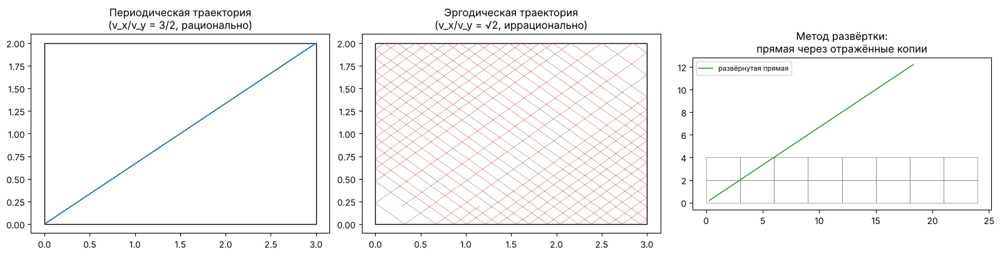

In [4]:
def billiard_trajectory(a, b, x0, y0, vx, vy, t_max, n=4000):
    # прямолинейное движение на плоскости, затем "складываем" координаты треугольной волной (метод развертки)
    t = np.linspace(0, t_max, n)
    X = x0 + vx*t                                         # незеркалированная прямая по x
    Y = y0 + vy*t                                         # незеркалированная прямая по y
    def fold(u, L):
        u_mod = np.mod(u, 2*L)                             # приводим к периоду 2L (полный цикл отражений)
        return np.where(u_mod <= L, u_mod, 2*L - u_mod)    # треугольная волна = траектория внутри [0, L]
    x = fold(X, a)
    y = fold(Y, b)
    return x, y

a_rect, b_rect = 3.0, 2.0                                  # стороны прямоугольника

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# периодический случай: v_x/v_y = 3/2 - рациональное отношение -> замкнутая траектория
x_p, y_p = billiard_trajectory(a_rect, b_rect, 0.3, 0.2, vx=3, vy=2, t_max=6, n=3000)
axes[0].plot(x_p, y_p, color='tab:blue', linewidth=1)
axes[0].add_patch(plt.Rectangle((0, 0), a_rect, b_rect, fill=False, edgecolor='black'))
axes[0].set_title('Периодическая траектория\n(v_x/v_y = 3/2, рационально)')
axes[0].set_aspect('equal')

# эргодический случай: v_x/v_y = sqrt(2) - иррациональное отношение -> плотно заполняет прямоугольник
x_e, y_e = billiard_trajectory(a_rect, b_rect, 0.3, 0.2, vx=np.sqrt(2), vy=1, t_max=60, n=40000)
axes[1].plot(x_e, y_e, color='tab:red', linewidth=0.3)
axes[1].add_patch(plt.Rectangle((0, 0), a_rect, b_rect, fill=False, edgecolor='black'))
axes[1].set_title('Эргодическая траектория\n(v_x/v_y = √2, иррационально)')
axes[1].set_aspect('equal')

# иллюстрация метода развертки: прямая линия через несколько зеркально отражённых копий прямоугольника
ax = axes[2]
t_un = np.linspace(0, 6, 400)
Xun = 0.3 + 3*t_un; Yun = 0.2 + 2*t_un                     # прямая на развёрнутой (неотражённой) плоскости
for i in range(int(Xun.max()/a_rect) + 2):                 # рисуем сетку отражённых копий прямоугольника
    ax.add_patch(plt.Rectangle((i*a_rect, 0), a_rect, b_rect, fill=False, edgecolor='gray', linewidth=0.5))
    ax.add_patch(plt.Rectangle((i*a_rect, b_rect), a_rect, b_rect, fill=False, edgecolor='gray', linewidth=0.5))
ax.plot(Xun, Yun, color='tab:green', linewidth=1.2, label='развёрнутая прямая')
ax.set_title('Метод развёртки:\nпрямая через отражённые копии'); ax.set_aspect('equal'); ax.legend(fontsize=8)

plt.tight_layout()
fig.savefig('Sol_3_2_static.png', dpi=150, bbox_inches='tight')
plt.show()

In [5]:
# Анимация: бильярдный шар отражается от стенок прямоугольника (периодический случай v_x/v_y=3/2)
a_an, b_an = 3.0, 2.0
t_anim = np.linspace(0, 6, 90)
x_an, y_an = billiard_trajectory(a_an, b_an, 0.3, 0.2, vx=3, vy=2, t_max=6, n=90)

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.add_patch(plt.Rectangle((0, 0), a_an, b_an, fill=False, edgecolor='black', linewidth=1.5))
trail, = ax.plot([], [], '-', color='tab:blue', linewidth=1, alpha=0.6)
ball, = ax.plot([], [], 'o', color='crimson', markersize=9)
txt = ax.text(0.02, 1.05, '', transform=ax.transAxes)
ax.set_xlim(-0.2, a_an + 0.2); ax.set_ylim(-0.2, b_an + 0.2)
ax.set_aspect('equal'); ax.set_title('Бильярд в прямоугольнике: упругие отражения')

def update32(i):
    trail.set_data(x_an[:i+1], y_an[:i+1])
    ball.set_data([x_an[i]], [y_an[i]])
    txt.set_text(f'кадр {i+1}/{len(t_anim)},  t = {t_anim[i]:.2f} c')
    return trail, ball, txt

ani32 = animation.FuncAnimation(fig, update32, frames=len(t_anim), interval=30, blit=True)
plt.close(fig)
HTML(ani32.to_jshtml())

**Вывод.** Код и анимация выше наглядно подтверждают теорию: при рациональном отношении скоростей $v_x/v_y$ траектория замыкается (периодический бильярд), при иррациональном — плотно заполняет прямоугольник (эргодический случай), а идея «развёртки» (правая картинка) показывает, как ломаная траектория бильярда превращается в обычную прямую на плоскости, замощённой зеркальными копиями прямоугольника.

## Задача 3.3. Цепная линия

**Постановка.** Однородная тяжёлая нерастяжимая нить (цепь) подвешена за два конца; требуется найти форму кривой равновесия.

### 1) Аналитическое решение

Рассмотрим элемент цепи длиной $ds$ между точками $x$ и $x+dx$. На концах элемента действуют силы натяжения $T(x)$, направленные по касательной к кривой, а также вес элемента $\rho g\,ds$ ($\rho$ — линейная плотность). Горизонтальная составляющая натяжения одинакова вдоль всей цепи (нет горизонтальных внешних сил) и равна $T_0=\text{const}$ — натяжению в самой низкой точке, где касательная горизонтальна.

Условие равновесия элемента по вертикали:
$$d(T\sin\varphi)=\rho g\,ds,$$
где $\varphi$ — угол наклона касательной, $\tan\varphi=y'(x)$. Так как горизонтальная проекция $T\cos\varphi=T_0=\text{const}$, вводим $p=y'=\tan\varphi$ и получаем
$$T_0\,dp=\rho g\,ds=\rho g\sqrt{1+p^2}\,dx \quad\Longrightarrow\quad \frac{dp}{\sqrt{1+p^2}}=\frac{\rho g}{T_0}\,dx=\frac1a\,dx,\qquad a:=\frac{T_0}{\rho g}.$$

Интегрируя (и выбирая начало координат в нижней точке цепи, где $p(0)=0$):
$$\operatorname{arsh}(p)=\frac xa \quad\Longrightarrow\quad p=y'=\operatorname{sh}\frac xa.$$

Интегрируя ещё раз ($y(0)=a$ — выбор постоянной интегрирования так, чтобы минимум кривой был на высоте $a$):
$$\boxed{\,y=a\,\operatorname{ch}\dfrac{x}{a}\,}.$$

**Физический смысл параметра $a=T_0/(\rho g)$:** это отношение горизонтального натяжения к весу единицы длины — чем больше натяжение $T_0$ (при той же плотности), тем больше $a$ и тем **более пологой** (менее провисающей) получается цепь; при малом $a$ цепь провисает глубоко.

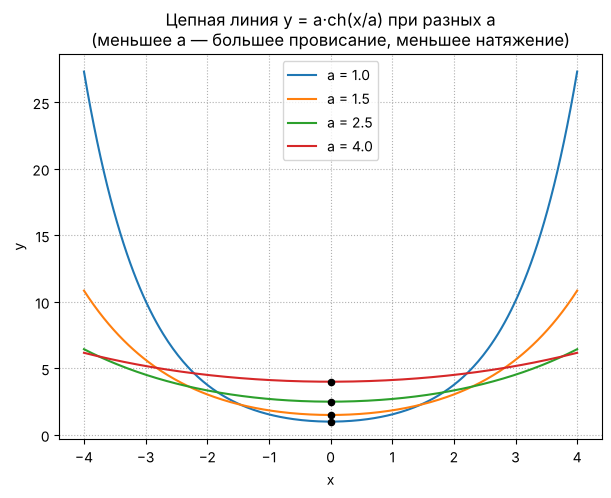

In [6]:
def catenary(a, xmax=4, n=300):
    x = np.linspace(-xmax, xmax, n)
    y = a*np.cosh(x/a)                                     # уравнение цепной линии y = a*ch(x/a)
    return x, y

fig, ax = plt.subplots()
for a in [1.0, 1.5, 2.5, 4.0]:                              # разные значения параметра a = T0/(rho*g)
    x, y = catenary(a)
    ax.plot(x, y, label=f'a = {a}')
    ax.scatter([0], [a], s=20, color='black', zorder=5)     # нижняя точка цепи (x=0, y=a)
ax.set_xlabel('x'); ax.set_ylabel('y')
ax.set_title('Цепная линия y = a·ch(x/a) при разных a\n(меньшее a — большее провисание, меньшее натяжение)')
ax.grid(True, linestyle=':'); ax.legend()
fig.savefig('Sol_3_3_static.png', dpi=150, bbox_inches='tight')
plt.show()

In [7]:
# Анимация: меняем параметр a во времени, показывая переход от сильно провисающей к пологой цепи
a_vals = 0.8 + 2.2*(1 + np.sin(np.linspace(-np.pi/2, 3*np.pi/2, 60)))/2   # a колеблется между 0.8 и 3.0
xmax = 4

fig, ax = plt.subplots(figsize=(5.5, 4))
line, = ax.plot([], [], color='tab:brown', linewidth=2.5)
pt, = ax.plot([], [], 'o', color='black')
txt = ax.text(0.02, 0.95, '', transform=ax.transAxes, va='top')
ax.set_xlim(-xmax, xmax); ax.set_ylim(0, 8)
ax.set_xlabel('x'); ax.set_ylabel('y'); ax.grid(True, linestyle=':')
ax.set_title('Анимация: изменение формы цепи при изменении параметра a = T0/(ρg)')

def update33(i):
    a = a_vals[i]
    x, y = catenary(a, xmax=xmax)
    line.set_data(x, y)
    pt.set_data([0], [a])
    sag = y[0] - a                                          # провисание относительно нижней точки на краях
    txt.set_text(f'a = {a:.2f}   (провисание на краях: {sag:.2f})')
    return line, pt, txt

ani33 = animation.FuncAnimation(fig, update33, frames=len(a_vals), interval=60, blit=True)
plt.close(fig)
HTML(ani33.to_jshtml())

**Вывод.** Форма равновесия тяжёлой нити — цепная линия $y=a\operatorname{ch}(x/a)$; анимация наглядно показывает, что уменьшение параметра $a$ (т.е. уменьшение горизонтального натяжения относительно веса) увеличивает провисание цепи, а увеличение $a$ делает цепь более пологой.

## Задача 3.4. Таутохрона (задача о таутохроне)

**Постановка.** Найти кривую, скатываясь по которой без трения под действием силы тяжести из любой точки, материальная точка достигает нижней точки кривой **за одно и то же время**, независимо от начального положения.

### 1) Аналитическое решение

**Интегральное уравнение.** Пусть кривая задана как $s=s(y)$ (длина дуги от нижней точки до точки на высоте $y$ над нижней точкой). Если тело стартует из состояния покоя с высоты $y_0$, то на высоте $y<y_0$ по закону сохранения энергии его скорость $v=\sqrt{2g(y_0-y)}$, а время спуска
$$\tau(y_0)=\int_0^{y_0}\frac{ds/dy\,dy}{\sqrt{2g(y_0-y)}}.$$
Требование $\tau(y_0)=T=\text{const}$ для всех $y_0$ — это **интегральное уравнение Абеля** относительно неизвестной функции $f(y):=ds/dy$:
$$T=\int_0^{y_0}\frac{f(y)\,dy}{\sqrt{y_0-y}}.$$

**Решение уравнения Абеля** (известная формула обращения) даёт $f(y)=\dfrac{\text{const}}{\sqrt y}$, то есть
$$\frac{ds}{dy}=\frac{k}{\sqrt y}\quad\Longrightarrow\quad \left(\frac{dx}{dy}\right)^2+1=\frac{k^2}{y}\quad\Longrightarrow\quad \frac{dx}{dy}=\sqrt{\frac{k^2-y}{y}}.$$

Это в точности дифференциальное уравнение **циклоиды** (ровно та же кривая, что в задаче о брахистохроне!). Его решение в параметрической форме при $k^2=2R$:
$$\boxed{\;x(\theta)=R(\theta-\sin\theta),\qquad y(\theta)=R(1-\cos\theta),\quad \theta\in[0,2\pi]\;}$$
— циклоида, порождённая качением окружности радиуса $R$ (точка $\theta=\pi$ — самая нижняя).

**Доказательство независимости времени спуска от начальной точки.** Введём $u=\cos(\theta/2)$. Из закона сохранения энергии при старте из покоя в точке $\theta_0$ и с учётом $\dfrac{ds}{d\theta}=2R\sin(\theta/2)$, $y(\theta)=2R\sin^2(\theta/2)$ получаем (см. выкладку в коде ниже, воспроизводящую классический результат):
$$\left(\frac{du}{dt}\right)^2=\frac{g}{4R}\left(u_0^2-u^2\right)\quad\Longrightarrow\quad u(t)=u_0\cos(\omega t),\qquad \omega=\sqrt{\frac{g}{4R}} .$$
Это **уравнение гармонических колебаний** для величины $u=\cos(\theta/2)$! Время достижения низшей точки ($\theta=\pi$, т.е. $u=0$) равно
$$t^{*}=\frac{\pi}{2\omega}=\pi\sqrt{\frac{R}{g}}$$
— выражение, **не зависящее от $\theta_0$** (а значит, и от начальной высоты $y_0=2R\sin^2(\theta_0/2)$). Это и есть свойство таутохронности циклоиды.

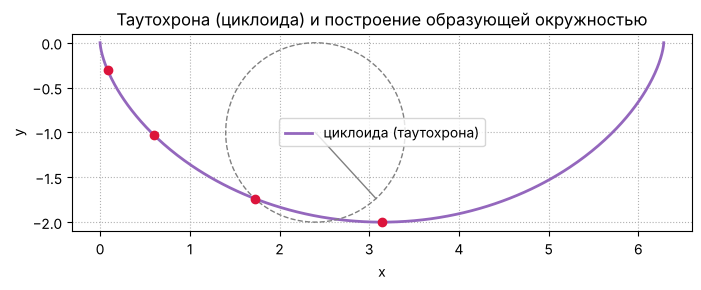

In [8]:
R = 1.0                                                     # радиус образующей окружности циклоиды
theta = np.linspace(0, 2*np.pi, 400)
x_cyc = R*(theta - np.sin(theta))
y_cyc = -R*(1 - np.cos(theta))                              # минус, чтобы кривая "падала" вниз на экране

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(x_cyc, y_cyc, color='tab:purple', linewidth=2, label='циклоида (таутохрона)')

# несколько стартовых точек на разной высоте + геометрическое построение (образующая окружность)
for theta0 in [0.8, 1.6, 2.4, np.pi]:
    x0c = R*(theta0 - np.sin(theta0)); y0c = -R*(1 - np.cos(theta0))
    ax.scatter([x0c], [y0c], color='crimson', zorder=5)

# рисуем образующую окружность в одном положении, чтобы проиллюстрировать способ построения циклоиды
theta_c = 2.4
cx, cy = R*theta_c, -R                                      # центр катящейся окружности при параметре theta_c
circ_phi = np.linspace(0, 2*np.pi, 100)
ax.plot(cx + R*np.cos(circ_phi), cy + R*np.sin(circ_phi), color='gray', linestyle='--', linewidth=1)
ax.plot([cx, cx + R*np.sin(theta_c)], [cy, cy + R*np.cos(theta_c)], color='gray', linewidth=1)  # радиус к точке контакта с кривой

ax.set_xlabel('x'); ax.set_ylabel('y')
ax.set_title('Таутохрона (циклоида) и построение образующей окружностью')
ax.grid(True, linestyle=':'); ax.legend()
ax.set_aspect('equal')
fig.savefig('Sol_3_4_static.png', dpi=150, bbox_inches='tight')
plt.show()

In [9]:
# Анимация: несколько шариков стартуют из разных точек циклоиды одновременно и достигают низа ОДНОВРЕМЕННО
omega = np.sqrt(g/(4*R))                                    # частота "гармонических колебаний" величины u=cos(theta/2)
t_star = np.pi/omega/2                                       # время достижения дна (одинаково для всех!)
theta0_list = [0.8, 1.6, 2.4, 3.0]                           # стартовые параметры theta_0 (разные высоты)
n_frames = 70
t_vals = np.linspace(0, t_star, n_frames)

def theta_of_t(theta0, t):
    u0 = np.cos(theta0/2)
    u = u0*np.cos(omega*t)                                   # решение уравнения гармонических колебаний
    u = np.clip(u, -1, 1)
    return 2*np.arccos(u)                                    # обратная замена theta = 2*arccos(u)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(x_cyc, y_cyc, color='lightgray', linewidth=2, zorder=1)
balls = [ax.plot([], [], 'o', markersize=10, zorder=5, label=f'θ₀={th0}')[0] for th0 in theta0_list]
txt = ax.text(0.02, 0.05, '', transform=ax.transAxes)
ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_aspect('equal')
ax.set_title('Таутохронность циклоиды: разные старты — одно время прихода в нижнюю точку')
ax.legend(loc='upper right', fontsize=8); ax.grid(True, linestyle=':')

def update34(i):
    t = t_vals[i]
    for ball, th0 in zip(balls, theta0_list):
        th = theta_of_t(th0, t)                              # текущий угол theta(t) для данного старта
        xb = R*(th - np.sin(th)); yb = -R*(1 - np.cos(th))
        ball.set_data([xb], [yb])
    txt.set_text(f't = {t:.3f} c  (все шарики достигнут дна одновременно при t* = {t_star:.3f} c)')
    return balls + [txt]

ani34 = animation.FuncAnimation(fig, update34, frames=n_frames, interval=40, blit=True)
plt.close(fig)
HTML(ani34.to_jshtml())

**Вывод.** Анимация наглядно демонстрирует главное свойство таутохроны: несмотря на разные начальные положения $\theta_0$ на циклоиде, все шарики достигают нижней точки в один и тот же момент времени $t^{*}=\pi\sqrt{R/g}$, что подтверждает аналитический вывод.

## Задача 3.5. Математический маятник

**Постановка.** Точечная масса $m$ на невесомом нерастяжимом стержне длины $L$ колеблется в поле тяжести без трения.

### 1) Аналитическое решение

**Уравнение движения.** Из второго закона Ньютона в проекции на касательное направление (или из уравнения Лагранжа для угла отклонения $\theta$ от вертикали):
$$mL\ddot\theta=-mg\sin\theta\quad\Longrightarrow\quad\boxed{\ddot\theta+\omega_0^2\sin\theta=0},\qquad\omega_0=\sqrt{g/L}.$$

**Линеаризация при малых углах.** При $\theta\ll1$, $\sin\theta\approx\theta$, уравнение сводится к гармоническому осциллятору $\ddot\theta+\omega_0^2\theta=0$ с решением $\theta(t)=\theta_0\cos(\omega_0t)$ и периодом, **не зависящим от амплитуды**: $T_0=2\pi/\omega_0=2\pi\sqrt{L/g}$.

**Точное (нелинейное) решение.** Уравнение $\ddot\theta+\omega_0^2\sin\theta=0$ имеет первый интеграл энергии
$$\frac12\dot\theta^2-\omega_0^2\cos\theta=E=\text{const}=-\omega_0^2\cos\theta_{\max}$$
(для колебательного режима с амплитудой $\theta_{\max}$). Точный период выражается через **полный эллиптический интеграл первого рода**:
$$T(\theta_{\max})=\frac{4}{\omega_0}K\!\left(\sin\frac{\theta_{\max}}2\right),\qquad K(k)=\int_0^{\pi/2}\frac{d\varphi}{\sqrt{1-k^2\sin^2\varphi}},$$
и при $\theta_{\max}\to\pi$ (маятник приближается к неустойчивому верхнему положению) $T\to\infty$ — это и отражает **сепаратриса** на фазовом портрете.

**Фазовый портрет.** В переменных $(\theta,\dot\theta)$ траектории — линии уровня «энергии» $E(\theta,\dot\theta)=\frac12\dot\theta^2-\omega_0^2\cos\theta$: замкнутые овалы вокруг $(\,0,0)$ при $E<\omega_0^2$ — **колебания**; незамкнутые «волнообразные» кривые при $E>\omega_0^2$ — **вращения** (маятник перекручивается через верх); граничная кривая $E=\omega_0^2$, проходящая через неустойчивые точки равновесия $\theta=\pm\pi$ — **сепаратриса**.

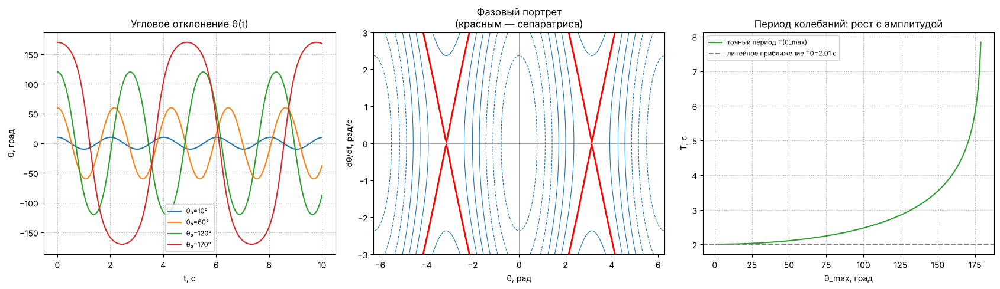

In [10]:
L_pend = 1.0
omega0 = np.sqrt(g/L_pend)                                    # собственная частота малых колебаний

def pendulum_rhs(t, state):
    theta, dtheta = state
    return [dtheta, -omega0**2*np.sin(theta)]                 # правая часть нелинейного уравнения маятника

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# a) графики theta(t) для разных начальных амплитуд (малые и большие углы)
ax = axes[0]
for theta0_deg in [10, 60, 120, 170]:
    theta0 = np.radians(theta0_deg)
    sol = solve_ivp(pendulum_rhs, [0, 10], [theta0, 0], dense_output=True, max_step=0.01)  # численное интегрирование ОДУ
    tt = np.linspace(0, 10, 500)
    ax.plot(tt, np.degrees(sol.sol(tt)[0]), label=f'θ₀={theta0_deg}°')
ax.set_xlabel('t, c'); ax.set_ylabel('θ, град'); ax.set_title('Угловое отклонение θ(t)')
ax.legend(fontsize=8); ax.grid(True, linestyle=':')

# b) фазовый портрет: линии уровня энергии E = 0.5*dtheta^2 - omega0^2*cos(theta)
ax = axes[1]
TH, DTH = np.meshgrid(np.linspace(-2*np.pi, 2*np.pi, 300), np.linspace(-3, 3, 300))
E = 0.5*DTH**2 - omega0**2*np.cos(TH)                          # "энергия" (сохраняющаяся величина)
levels = np.linspace(E.min(), omega0**2*3, 15)
ax.contour(TH, DTH, E, levels=levels, colors='tab:blue', linewidths=0.8)
ax.contour(TH, DTH, E, levels=[omega0**2], colors='red', linewidths=2)  # сепаратриса E = omega0^2
ax.set_xlabel('θ, рад'); ax.set_ylabel('dθ/dt, рад/с')
ax.set_title('Фазовый портрет\n(красным — сепаратриса)')
ax.axhline(0, color='gray', linewidth=0.5); ax.axvline(0, color='gray', linewidth=0.5)

# c) зависимость точного периода от амплитуды через эллиптический интеграл
ax = axes[2]
theta_max_deg = np.linspace(1, 179, 200)
theta_max = np.radians(theta_max_deg)
k = np.sin(theta_max/2)
T_exact = (4/omega0)*ellipk(k**2)                               # scipy.special.ellipk использует параметр m=k^2
T0 = 2*np.pi/omega0                                              # период линейного приближения (не зависит от амплитуды)
ax.plot(theta_max_deg, T_exact, color='tab:green', label='точный период T(θ_max)')
ax.axhline(T0, color='gray', linestyle='--', label=f'линейное приближение T0={T0:.2f} c')
ax.set_xlabel('θ_max, град'); ax.set_ylabel('T, c')
ax.set_title('Период колебаний: рост с амплитудой'); ax.legend(fontsize=8); ax.grid(True, linestyle=':')

plt.tight_layout()
fig.savefig('Sol_3_5_static.png', dpi=150, bbox_inches='tight')
plt.show()

In [11]:
# Анимация: физический маятник (слева) + его траектория на фазовой плоскости (справа), одновременно
theta0_anim = np.radians(150)                                  # большая амплитуда - хорошо видна нелинейность
sol_anim = solve_ivp(pendulum_rhs, [0, 8], [theta0_anim, 0], dense_output=True, max_step=0.01)
n_frames = 90
t_anim = np.linspace(0, 8, n_frames)
state_anim = sol_anim.sol(t_anim)                               # [theta(t), dtheta(t)] на равномерной сетке времени
theta_t, dtheta_t = state_anim[0], state_anim[1]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 3.8))

# левая панель - сам маятник (стержень + груз)
ax1.set_xlim(-1.3, 1.3); ax1.set_ylim(-1.3, 1.3); ax1.set_aspect('equal')
ax1.set_title('Движение маятника'); ax1.grid(True, linestyle=':')
rod, = ax1.plot([], [], '-', color='black', linewidth=2)
bob, = ax1.plot([], [], 'o', color='crimson', markersize=16)
txt1 = ax1.text(-1.25, 1.15, '')

# правая панель - фазовый портрет с движущейся точкой и следом
ax2.contour(TH, DTH, E, levels=levels, colors='tab:blue', linewidths=0.6)
ax2.contour(TH, DTH, E, levels=[omega0**2], colors='red', linewidths=1.5)
ax2.set_xlim(-np.pi-0.5, np.pi+0.5); ax2.set_ylim(-4, 4)
ax2.set_xlabel('θ, рад'); ax2.set_ylabel('dθ/dt, рад/с'); ax2.set_title('Фазовая траектория')
phase_trace, = ax2.plot([], [], color='darkorange', linewidth=1.5)
phase_pt, = ax2.plot([], [], 'o', color='darkorange', markersize=8)

def update35(i):
    th = theta_t[i]
    xb, yb = np.sin(th), -np.cos(th)                            # положение груза маятника (L=1)
    rod.set_data([0, xb], [0, yb])
    bob.set_data([xb], [yb])
    txt1.set_text(f't={t_anim[i]:.2f}c  θ={np.degrees(th):.1f}°')
    phase_trace.set_data(theta_t[:i+1], dtheta_t[:i+1])
    phase_pt.set_data([theta_t[i]], [dtheta_t[i]])
    return rod, bob, txt1, phase_trace, phase_pt

ani35 = animation.FuncAnimation(fig, update35, frames=n_frames, interval=50, blit=True)
plt.close(fig)
HTML(ani35.to_jshtml())

**Вывод.** При большой начальной амплитуде ($\theta_0=150^\circ$) хорошо видна нелинейность движения: маятник заметно «задерживается» вблизи верхних точек поворота (где фазовая траектория приближается к области вблизи сепаратрисы), а период колебаний заметно превышает линейное приближение $T_0$, что согласуется с графиком $T(\theta_{\max})$, построенным выше через эллиптический интеграл.